In [ ]:
#Variable	Description
#Item_Identifier - Unique product ID
#Item_Weight - Weight of product
#Item_Fat_Content	- Whether the product is low fat or not
#Item_Visibility - The % of total display area of all products in a store allocated to the particular product
#Item_Type - The category to which the product belongs
#Item_MRP - Maximum Retail Price (list price) of the product
#Outlet_Identifier - Unique store ID
#Outlet_Establishment_Year - The year in which store was established
#Outlet_Size - The size of the store in terms of ground area covered
#Outlet_Location_Type - The type of city in which the store is located
#Outlet_Type - Whether the outlet is just a grocery store or some sort of supermarket
#Item_Outlet_Sales - Sales of the product in the particular store. This is the outcome variable to be predicted.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import files

In [ ]:
uploaded=files.upload()

Saving train_v9rqX0R.csv to train_v9rqX0R.csv


In [ ]:
df=pd.read_csv("/content/train_v9rqX0R.csv")

In [ ]:
df.head()

,Item_Identifier,Item_Weight,Item_Fat_Content,Item_Visibility,Item_Type,Item_MRP,Outlet_Identifier,Outlet_Establishment_Year,Outlet_Size,Outlet_Location_Type,Outlet_Type,Item_Outlet_Sales
0,FDA15,9.30,Low Fat,0.016047,Dairy,249.8092,OUT049,1999,Medium,Tier 1,Supermarket Type1,3735.1380
1,DRC01,5.92,Regular,0.019278,Soft Drinks,48.2692,OUT018,2009,Medium,Tier 3,Supermarket Type2,443.4228
2,FDN15,17.50,Low Fat,0.016760,Meat,141.6180,OUT049,1999,Medium,Tier 1,Supermarket Type1,2097.2700
3,FDX07,19.20,Regular,0.000000,Fruits and Vegetables,182.0950,OUT010,1998,NaN,Tier 3,Grocery Store,732.3800
4,NCD19,8.93,Low Fat,0.000000,Household,53.8614,OUT013,1987,High,Tier 3,Supermarket Type1,994.7052


In [ ]:
df.shape

(8523, 12)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8523 entries, 0 to 8522
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Item_Identifier            8523 non-null   object 
 1   Item_Weight                7060 non-null   float64
 2   Item_Fat_Content           8523 non-null   object 
 3   Item_Visibility            8523 non-null   float64
 4   Item_Type                  8523 non-null   object 
 5   Item_MRP                   8523 non-null   float64
 6   Outlet_Identifier          8523 non-null   object 
 7   Outlet_Establishment_Year  8523 non-null   int64  
 8   Outlet_Size                6113 non-null   object 
 9   Outlet_Location_Type       8523 non-null   object 
 10  Outlet_Type                8523 non-null   object 
 11  Item_Outlet_Sales          8523 non-null   float64
dtypes: float64(4), int64(1), object(7)
memory usage: 799.2+ KB


In [ ]:
df.isnull().sum()

,0
Item_Identifier,0
Item_Weight,1463
Item_Fat_Content,0
Item_Visibility,0
Item_Type,0
Item_MRP,0
Outlet_Identifier,0
Outlet_Establishment_Year,0
Outlet_Size,2410
Outlet_Location_Type,0


In [ ]:
df.isnull().mean() * 100

,0
Item_Identifier,0.000000
Item_Weight,17.165317
Item_Fat_Content,0.000000
Item_Visibility,0.000000
Item_Type,0.000000
Item_MRP,0.000000
Outlet_Identifier,0.000000
Outlet_Establishment_Year,0.000000
Outlet_Size,28.276428
Outlet_Location_Type,0.000000


In [ ]:
numeric=df.select_dtypes(include='number').columns.to_list()
print(numeric)
categorical=df.select_dtypes(include='object').columns.to_list()
print(categorical)

['Item_Weight', 'Item_Visibility', 'Item_MRP', 'Outlet_Establishment_Year', 'Item_Outlet_Sales']
['Item_Identifier', 'Item_Fat_Content', 'Item_Type', 'Outlet_Identifier', 'Outlet_Size', 'Outlet_Location_Type', 'Outlet_Type']


In [ ]:
#Numeric Variable Analysis

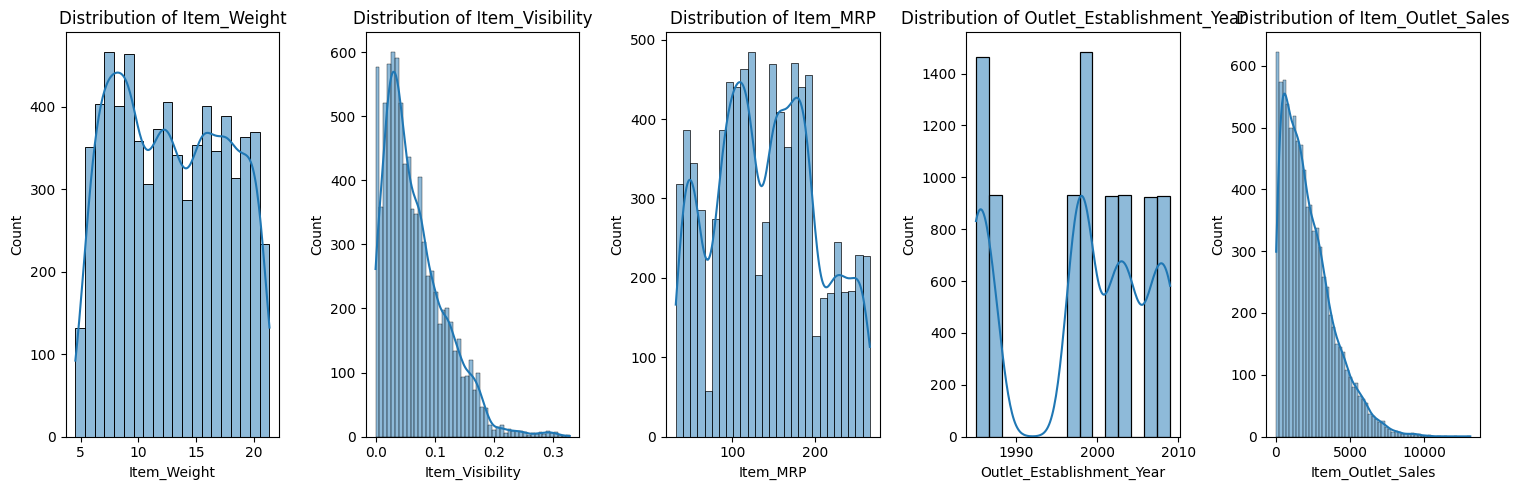

In [ ]:
plt.figure(figsize=(15, 5))

for i, col in enumerate(numeric):
    plt.subplot(1, 5, i + 1)

    sns.histplot(df[col], kde=True)
    plt.title(f'Distribution of {col}')

plt.tight_layout()
plt.show()

In [ ]:
#Item_Weight - is kind of platykurtic and high variance (also null values)
#Item_Visibility - is heavily right-skewed
#Item_MRP - has many peaks ie not ideal
#Outlet_Establishment_Year - huge gap in b/w and also has many peaks (date data)
#Item_Outlet_Sales - heavily right_skewed
#might exist a relation b/w Item_Visbility and Item_Outlet_Sales

In [ ]:
#Outlier Analysis

In [ ]:
df.describe()

,Item_Weight,Item_Visibility,Item_MRP,Outlet_Establishment_Year,Item_Outlet_Sales
count,7060.000000,8523.000000,8523.000000,8523.000000,8523.000000
mean,12.857645,0.066132,140.992782,1997.831867,2181.288914
std,4.643456,0.051598,62.275067,8.371760,1706.499616
min,4.555000,0.000000,31.290000,1985.000000,33.290000
25%,8.773750,0.026989,93.826500,1987.000000,834.247400
50%,12.600000,0.053931,143.012800,1999.000000,1794.331000
75%,16.850000,0.094585,185.643700,2004.000000,3101.296400
max,21.350000,0.328391,266.888400,2009.000000,13086.964800


In [ ]:
df[numeric].median()

,0
Item_Weight,12.600000
Item_Visibility,0.053931
Item_MRP,143.012800
Outlet_Establishment_Year,1999.000000
Item_Outlet_Sales,1794.331000


In [ ]:
print(df[df['Item_Visibility'] == 0]['Item_Outlet_Sales'])

3        732.3800
4        994.7052
5        556.6088
10      1516.0266
32      3068.0064
          ...    
8480     459.4020
8484    2324.9736
8486      45.2744
8494    1637.8680
8500    1907.5170
Name: Item_Outlet_Sales, Length: 526, dtype: float64


In [ ]:
#Item_Visibility has its minimum value as 0 which shouldnt be possible since having so would mean 0 sales but that is not the case
#so we will treat them as null values

In [ ]:
df['Item_Visibility']=df['Item_Visibility'].replace(0,np.nan)

In [ ]:
#possible outliers in - Item_Visibility(high), Item_MRP(doubt)

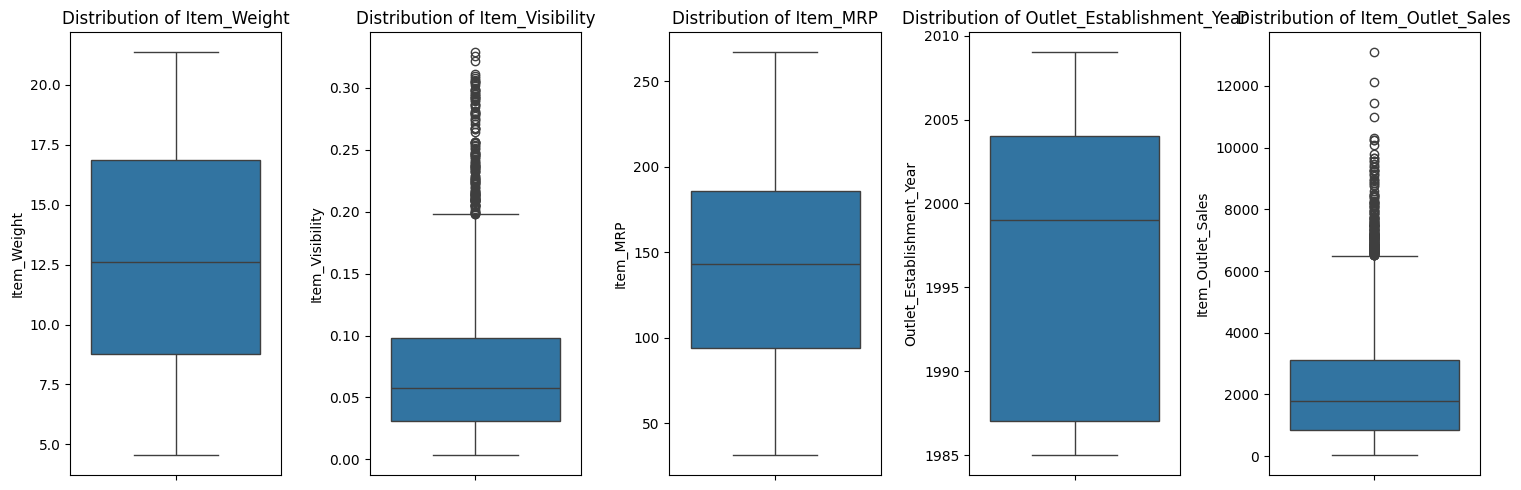

In [ ]:
plt.figure(figsize=(15, 5))

for i, col in enumerate(numeric):
    plt.subplot(1, 5, i + 1)

    sns.boxplot(df[col])
    plt.title(f'Distribution of {col}')

plt.tight_layout()
plt.show()

In [ ]:
#Item_Visibility (Solved by removing outliers)

In [ ]:
#IQR test
lower=df['Item_Visibility'].quantile(0.25)
upper=df['Item_Visibility'].quantile(0.75)
iqr=upper-lower
lower_boundIQR=lower-(1.5*iqr)
upper_boundIQR=upper+(1.5*iqr)
outliersIQR=df[(df['Item_Visibility']>upper_boundIQR)]
print(outliersIQR['Item_Visibility'])
print(len(outliersIQR['Item_Visibility']))
print(upper_boundIQR)

49      0.255395
83      0.293418
108     0.278974
174     0.291865
334     0.204700
          ...   
8292    0.209163
8345    0.266397
8371    0.214125
8432    0.227261
8509    0.214306
Name: Item_Visibility, Length: 140, dtype: float64
140
0.198167231


In [ ]:
#mean+-3sigma test
m = df['Item_Visibility'].mean()
s = df['Item_Visibility'].std()
lower_boundM3 = m - 3*s
upper_boundM3 = m + 3*s
outliersM3 = df[(df['Item_Visibility'] > upper_boundM3)]
print(outliersM3['Item_Visibility'])
print(len(outliersM3['Item_Visibility']))
print(upper_boundM3)

49      0.255395
83      0.293418
108     0.278974
174     0.291865
434     0.264125
          ...   
8194    0.299098
8215    0.279887
8273    0.297313
8345    0.266397
8432    0.227261
Name: Item_Visibility, Length: 95, dtype: float64
95
0.22140451139549866


In [ ]:
#percentile test
p99=np.percentile(df['Item_Visibility'],99)
outliersP=df[df['Item_Visibility']>p99]
print(outliersP['Item_Visibility'])
print(len(outliersP['Item_Visibility']))
print(p99)

Series([], Name: Item_Visibility, dtype: float64)
0
nan


In [ ]:
#we will move forward with the upper bound from the Percentile test as it is the higehst out of all three tests, and doing so will lead to less
#removal of values and not cause a pak at the end of the distribution

In [ ]:
df['Item_Visibility_1']=np.where(df['Item_Visibility']>p99,p99,df['Item_Visibility'])

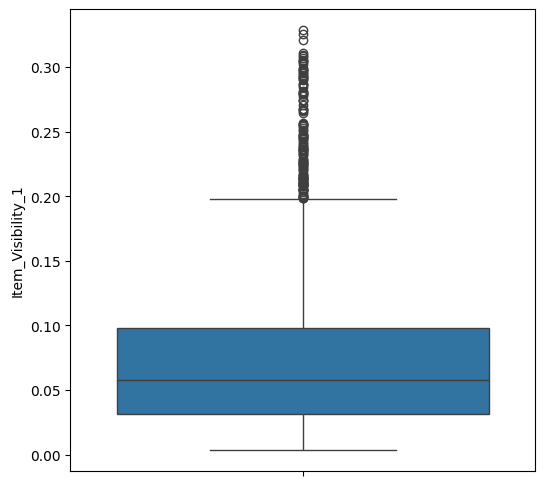

In [ ]:
plt.figure(figsize=(6,6))
sns.boxplot(df['Item_Visibility_1'])
plt.show()

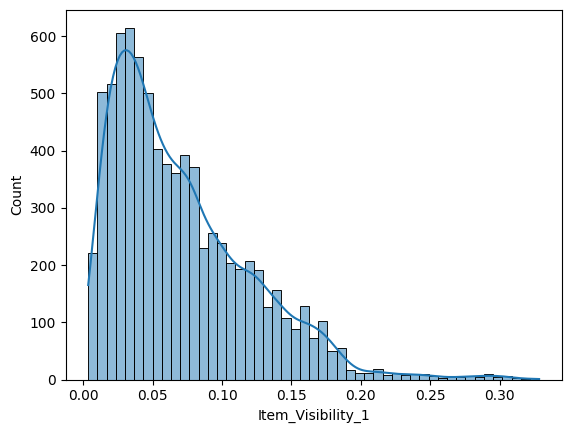

In [ ]:
sns.histplot(df['Item_Visibility_1'],kde=True)
plt.show()

In [ ]:
#Item_MRP

In [ ]:
#IQR test
lower=df['Item_MRP'].quantile(0.25)
upper=df['Item_MRP'].quantile(0.75)
iqr=upper-lower
lower_boundIQR=lower-(1.5*iqr)
upper_boundIQR=upper+(1.5*iqr)
outliersIQR=df[(df['Item_MRP']>upper_boundIQR)]
print(outliersIQR['Item_MRP'])
print(len(outliersIQR['Item_MRP']))
print(upper_boundIQR)

Series([], Name: Item_MRP, dtype: float64)
0
323.3695


In [ ]:
#mean+-3sigma test
m = df['Item_MRP'].mean()
s = df['Item_MRP'].std()
lower_boundM3 = m - 3*s
upper_boundM3 = m + 3*s
outliersM3 = df[(df['Item_MRP'] > upper_boundM3)]
print(outliersM3['Item_MRP'])
print(len(outliersM3['Item_MRP']))
print(upper_boundM3)

Series([], Name: Item_MRP, dtype: float64)
0
327.8179815147479


In [ ]:
#percentile test
p99=np.percentile(df['Item_MRP'],99)
outliersP=df[df['Item_MRP']>p99]
print(outliersP['Item_MRP'])
print(len(outliersP['Item_MRP']))
print(p99)

47      265.2226
191     264.7568
212     263.7568
273     264.0884
502     263.4568
          ...   
7999    263.2594
8198    263.6594
8375    266.0226
8410    263.6910
8506    263.1910
Name: Item_MRP, Length: 85, dtype: float64
85
263.0226


In [ ]:
#we will leave Item_MRP alone

In [ ]:
#Null Value Imputation

In [ ]:
df.isnull().sum()

,0
Item_Identifier,0
Item_Weight,1463
Item_Fat_Content,0
Item_Visibility,526
Item_Type,0
Item_MRP,0
Outlet_Identifier,0
Outlet_Establishment_Year,0
Outlet_Size,2410
Outlet_Location_Type,0


In [ ]:
df.isnull().mean() * 100

,0
Item_Identifier,0.000000
Item_Weight,17.165317
Item_Fat_Content,0.000000
Item_Visibility,6.171536
Item_Type,0.000000
Item_MRP,0.000000
Outlet_Identifier,0.000000
Outlet_Establishment_Year,0.000000
Outlet_Size,28.276428
Outlet_Location_Type,0.000000


In [ ]:
#null values in - Item_weight, Item_Visibility_1, Outlet_Size(categorical so will deal with it later)

In [ ]:
df['Item_Weight']=df['Item_Weight'].fillna(df['Item_Weight'].median())
df['Item_Visibility_1']=df['Item_Visibility_1'].fillna(df['Item_Visibility_1'].median())

In [ ]:
df[['Item_Weight','Item_Visibility_1']].isnull().sum()

,0
Item_Weight,0
Item_Visibility_1,0


In [ ]:
#Distribution fixation

In [ ]:
#Item_Weight - is kind of platykurtic and has high variance
#Item_Visibility - is heavily right-skewed
#Item_MRP - has many peaks ie not ideal
#Outlet_Establishment_Year - huge gap in b/w and also has many peaks (date data)
#Item_Outlet_Sales - heavily right_skewed

In [ ]:
#Item_Weight

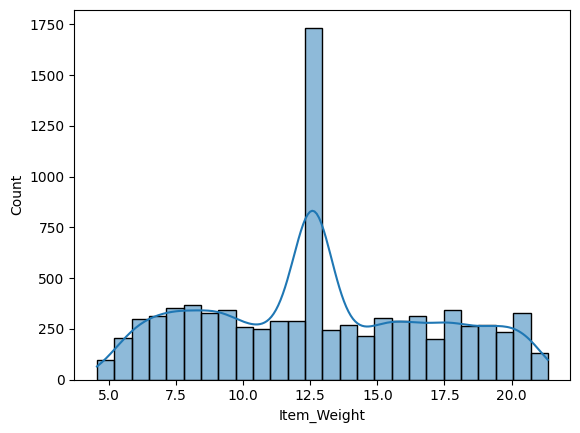

In [ ]:
sns.histplot(df['Item_Weight'],kde=True)
plt.show()

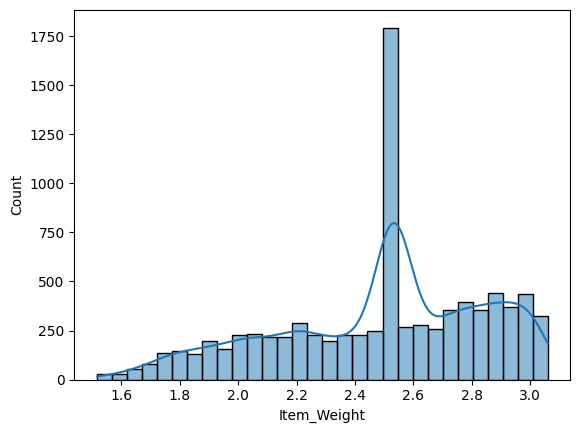

In [ ]:
sns.histplot(np.log(df['Item_Weight']),kde=True)
plt.show()

In [ ]:
print(df['Item_Weight'].var())
print(np.log(df['Item_Weight']).var())

17.869561454073366
0.1287838180724695


In [ ]:
#since the variance is less in log form, we will use Item_Weight_log

In [ ]:
df['Item_Weight_log']=np.log(df['Item_Weight'])

In [ ]:
#Outlet_Establishment_Year

In [ ]:
df['Outlet_Establishment_Year'].unique()

array([1999, 2009, 1998, 1987, 1985, 2002, 2007, 1997, 2004])

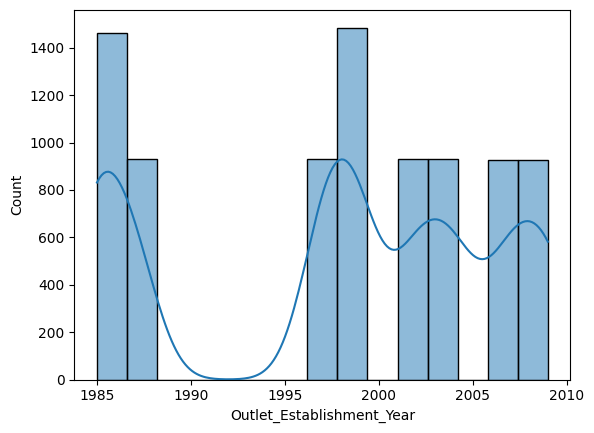

In [ ]:
sns.histplot(df['Outlet_Establishment_Year'],kde=True)
plt.show()

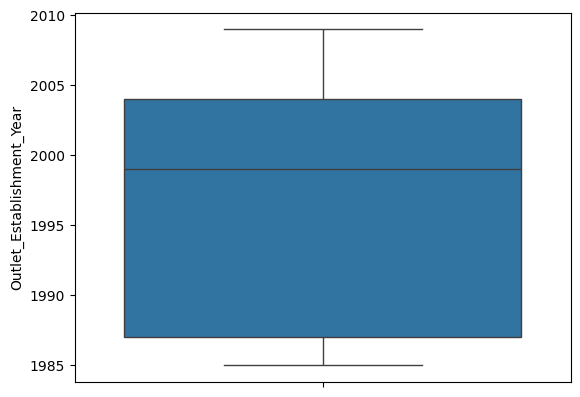

In [ ]:
sns.boxplot(df['Outlet_Establishment_Year'])
plt.show()

In [ ]:
#there are no outliers in the Outlet_Establishment_Year column
#two approaches we can take
#we can transform this column into the number of years the outlet has existed as it can affect the trust it has earned from the customers
#of the city
#also possible to treat this as categorical because of less unique values
#hence will create two datasets one with it and one without

In [ ]:
df['Outlet_Existed_years']=2026-df['Outlet_Establishment_Year']

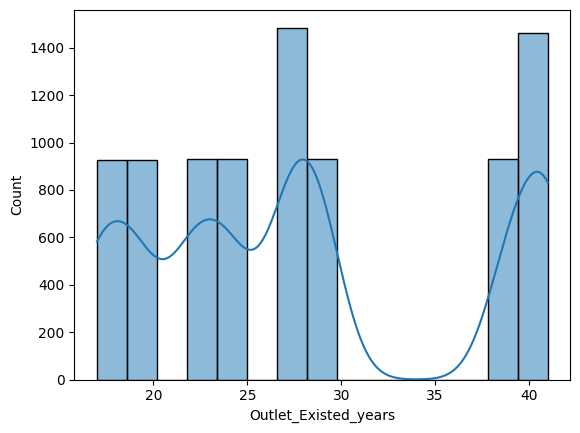

In [ ]:
sns.histplot(df['Outlet_Existed_years'],kde=True)
plt.show()

In [ ]:
#Categorical Analysis

In [ ]:
print(categorical)

['Item_Identifier', 'Item_Fat_Content', 'Item_Type', 'Outlet_Identifier', 'Outlet_Size', 'Outlet_Location_Type', 'Outlet_Type']


In [ ]:
categorical.remove('Item_Identifier')

In [ ]:
categorical.remove("Outlet_Identifier")

In [ ]:
df[categorical]=df[categorical].apply(lambda x:x.str.strip().str.lower())
for i in categorical:
  print(i,df[i].unique())

Item_Fat_Content ['low fat' 'regular' 'lf' 'reg']
Item_Type ['dairy' 'soft drinks' 'meat' 'fruits and vegetables' 'household'
 'baking goods' 'snack foods' 'frozen foods' 'breakfast'
 'health and hygiene' 'hard drinks' 'canned' 'breads' 'starchy foods'
 'others' 'seafood']
Outlet_Size ['medium' nan 'high' 'small']
Outlet_Location_Type ['tier 1' 'tier 3' 'tier 2']
Outlet_Type ['supermarket type1' 'supermarket type2' 'grocery store'
 'supermarket type3']


In [ ]:
#standardization of values using dictionary
cleaning_map = {
    "Item_Fat_Content": {
        "low fat": "Low Fat",
        "lf": "Low Fat",
        "regular": "Regular",
        "reg": "Regular",
    },
    "Item_Type": {
        "dairy": "Dairy",
        "soft drinks": "Soft Drinks",
        "meat": "Meat",
        "fruits and vegetables": "Fruits & Vegetables",
        "household": "Household",
        "baking goods": "Baking Goods",
        "snack foods": "Snack Foods",
        "frozen foods": "Frozen Foods",
        "breakfast": "Breakfast",
        "health and hygiene": "Health & Hygiene",
        "hard drinks": "Hard Drinks",
        "canned": "Canned Goods",
        "breads": "Breads",
        "starchy foods": "Starchy Foods",
        "others": "Others",
        "seafood": "Seafood",
    },
    "Outlet_Size": {
        "small": "Small",
        "medium": "Medium",
        "high": "High",
        np.nan: "Unknown",
        "nan": "Unknown",
    },
    "Outlet_Location_Type": {
        "tier 1": "Tier 1",
        "tier 2": "Tier 2",
        "tier 3": "Tier 3",
    },
    "Outlet_Type": {
        "grocery store": "Grocery Store",
        "supermarket type1": "Supermarket Type 1",
        "supermarket type2": "Supermarket Type 2",
        "supermarket type3": "Supermarket Type 3",
    },
}

In [ ]:
for col, mapping in cleaning_map.items():
    if col in df.columns:
        df[col] = df[col].replace(mapping)

In [ ]:
for col in categorical:
  print("Value Counts: ")
  print(df[col].value_counts())
  print("\n")

Value Counts: 
Item_Fat_Content
Low Fat    5517
Regular    3006
Name: count, dtype: int64


Value Counts: 
Item_Type
Fruits & Vegetables    1232
Snack Foods            1200
Household               910
Frozen Foods            856
Dairy                   682
Canned Goods            649
Baking Goods            648
Health & Hygiene        520
Soft Drinks             445
Meat                    425
Breads                  251
Hard Drinks             214
Others                  169
Starchy Foods           148
Breakfast               110
Seafood                  64
Name: count, dtype: int64


Value Counts: 
Outlet_Size
Medium     2793
Unknown    2410
Small      2388
High        932
Name: count, dtype: int64


Value Counts: 
Outlet_Location_Type
Tier 3    3350
Tier 2    2785
Tier 1    2388
Name: count, dtype: int64


Value Counts: 
Outlet_Type
Supermarket Type 1    5577
Grocery Store         1083
Supermarket Type 3     935
Supermarket Type 2     928
Name: count, dtype: int64




In [ ]:
#Item_Fat_Content - has an order present (ordinal encoding)
#Item_Type - different and unrelated values (on-hot for linear and target for xgboost)
#Outlet_Size - has an order present (ordinal encoding)
#Outlet_Location_Type - has an order present (ordinal encoding)
#Outlet_Type - an order might be present (will decide)

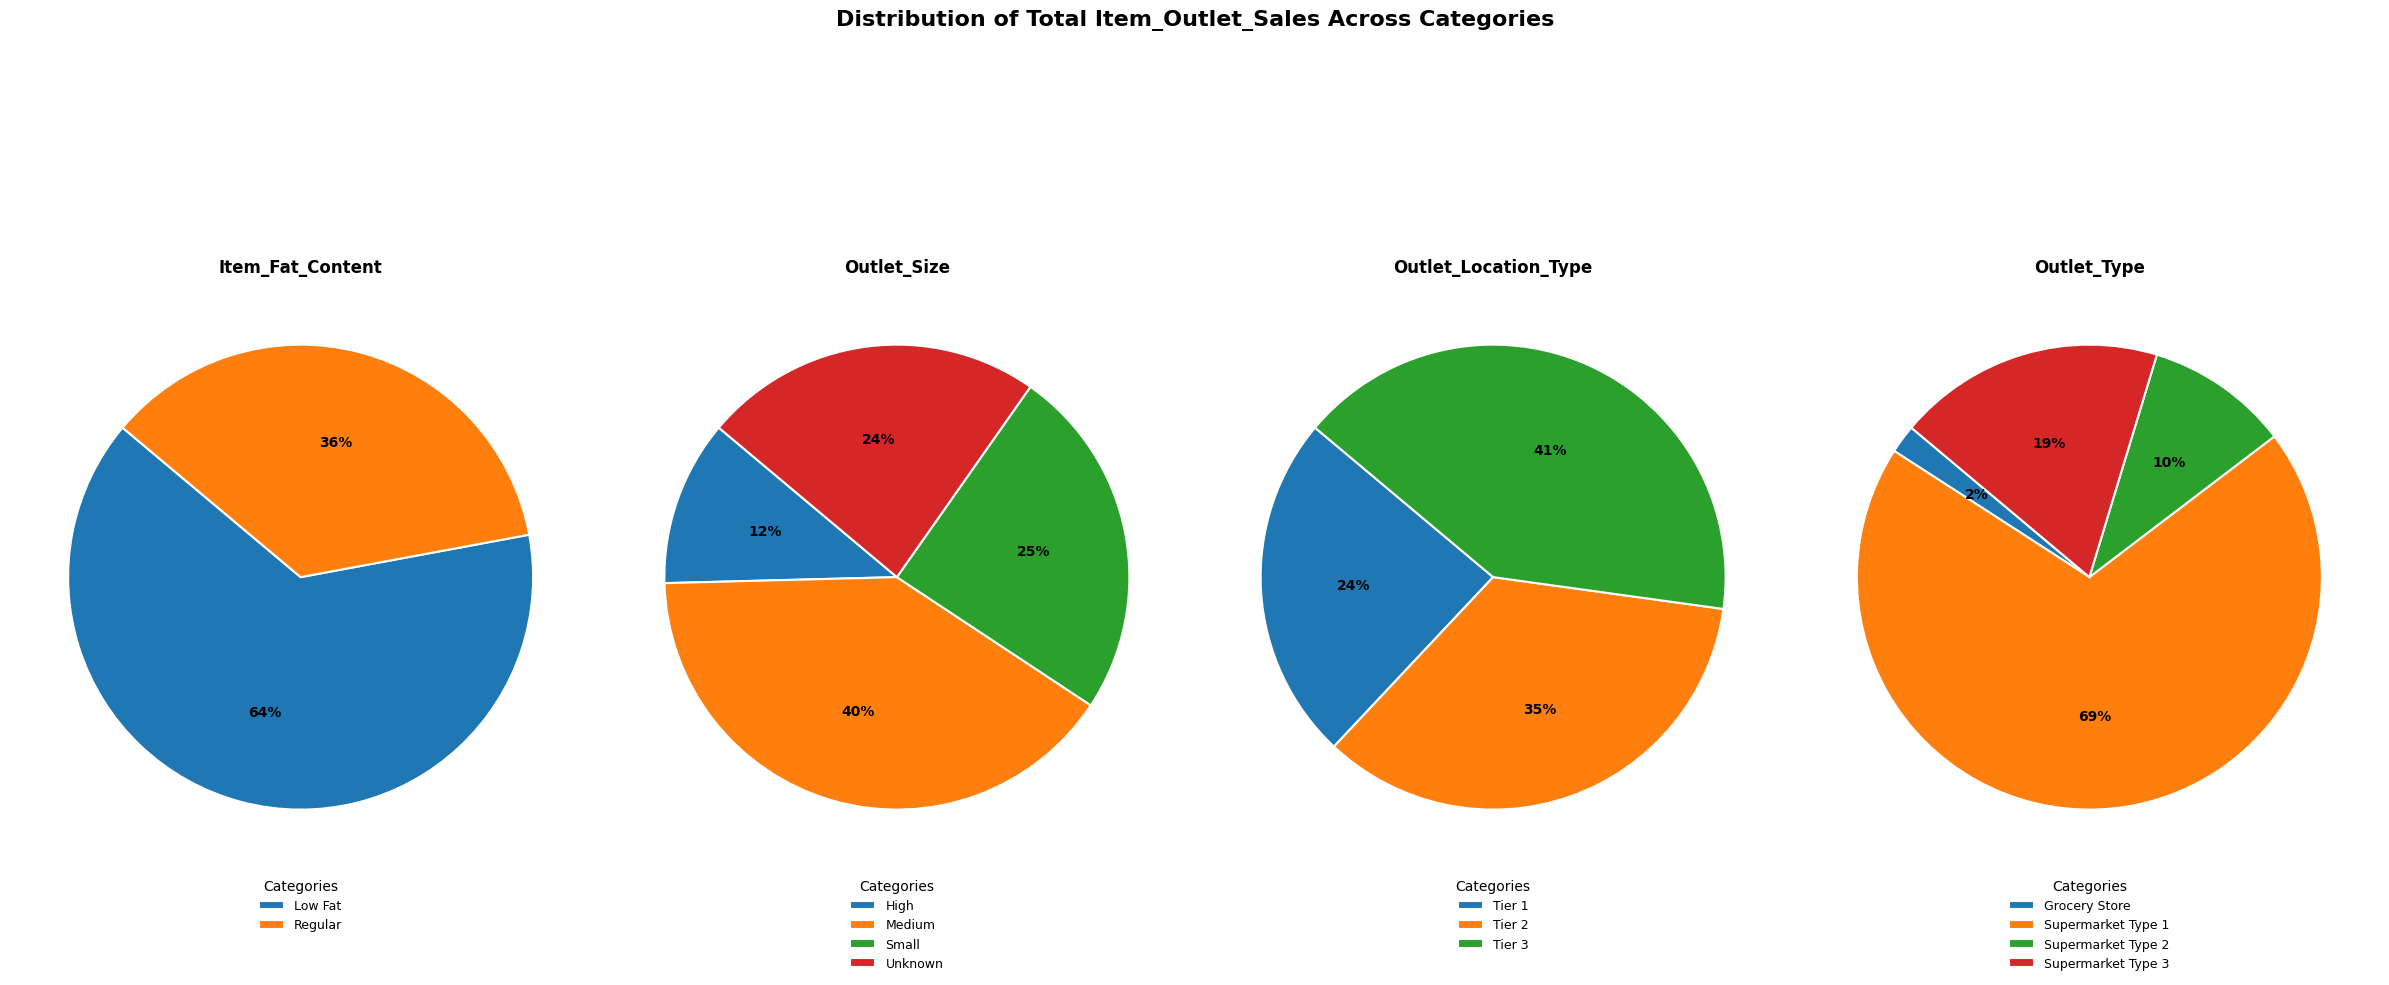

In [ ]:
categorical_cols = [
    "Item_Fat_Content",
    "Outlet_Size",
    "Outlet_Location_Type",
    "Outlet_Type",
]
numeric_col = "Item_Outlet_Sales"

fig, axes = plt.subplots(1, 4, figsize=(24, 10))

for i, col in enumerate(categorical_cols):
    # Aggregate sales data for the current column
    chart_data = df.groupby(col)[numeric_col].sum().reset_index()

    # Smart grouping for 'Item_Type' to keep the row clean
    if col == "Item_Type" and len(chart_data) > 5:
        chart_data = chart_data.sort_values(by=numeric_col, ascending=False)
        top_n = chart_data.head(4)
        other_sales = chart_data.iloc[4:][numeric_col].sum()
        other_row = pd.DataFrame({col: ["Other"], numeric_col: [other_sales]})
        chart_data = pd.concat([top_n, other_row], ignore_index=True)

    # Plot the pie chart on the specific axis slot (axes[i])
    wedges, texts, autotexts = axes[i].pie(
        chart_data[numeric_col],
        autopct="%1.0f%%",  # Cleaner integers for tighter horizontal spaces
        startangle=140,
        wedgeprops={"edgecolor": "white", "linewidth": 1.5},
        textprops={"fontsize": 10, "weight": "bold"},
    )

    # Style the percentages inside the slices to stand out
    plt.setp(autotexts, size=10, weight="bold")

    # Set sub-titles for each chart
    axes[i].set_title(col, fontsize=12, weight="bold", pad=10)

    # Add a compact legend below each individual pie chart
    axes[i].legend(
        wedges,
        chart_data[col],
        title="Categories",
        loc="upper center",
        bbox_to_anchor=(0.5, 0.0),  # Places legend directly beneath the pie
        fontsize=9,
        frameon=False,
    )

# Super-title for the entire row
plt.suptitle(
    f"Distribution of Total {numeric_col} Across Categories",
    fontsize=16,
    weight="bold",
    y=1.05,
)

# Render everything seamlessly without clipping text
plt.tight_layout()
plt.show()

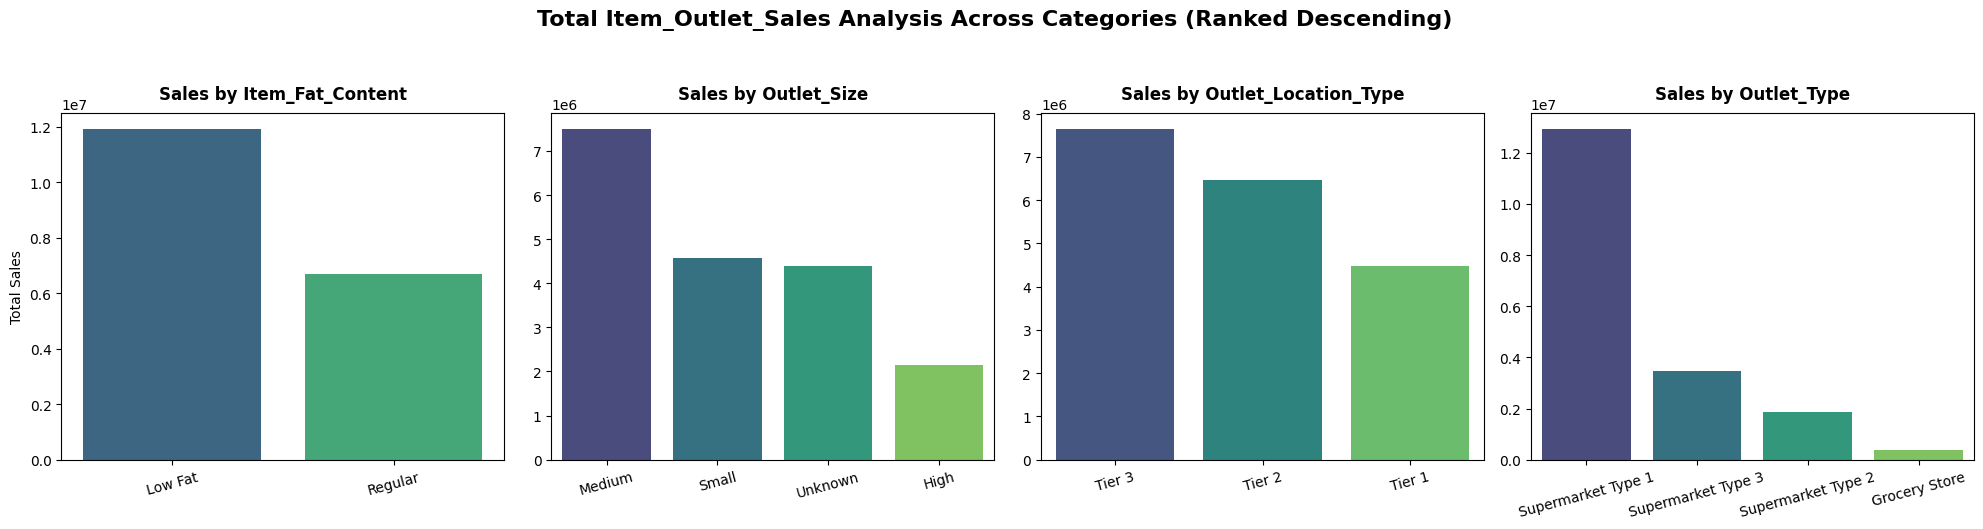

In [ ]:
categorical_cols = [
    "Item_Fat_Content",
    "Outlet_Size",
    "Outlet_Location_Type",
    "Outlet_Type"
]
numeric_col = "Item_Outlet_Sales"

fig, axes = plt.subplots(1, 4, figsize=(20, 5))

for i, col in enumerate(categorical_cols):
    # Aggregate sales data and sort in descending order
    chart_data = (
        df.groupby(col)[numeric_col]
        .sum()
        .sort_values(ascending=False)
        .reset_index()
    )

    # Plot the bar chart using Seaborn on the specific axis slot (axes[i])
    sns.barplot(
        x=col,
        y=numeric_col,
        data=chart_data,
        ax=axes[i],
        palette="viridis",  # Clean, modern color spectrum
        hue=col,  # Assigns distinct colors to each bar category
        legend=False,  # Suppresses the redundant legend box
    )

    # Visual enhancements for each subplot
    axes[i].set_title(f"Sales by {col}", fontsize=12, weight="bold", pad=10)
    axes[i].set_xlabel("")  # Hides the redundant x-axis label string
    axes[i].set_ylabel("Total Sales" if i == 0 else "")  # Only labels y-axis on the leftmost chart

    # Rotate labels slightly if they are long (like in Outlet_Type)
    axes[i].tick_params(axis="x", rotation=15)

# Add a single super-title for the entire grid
plt.suptitle(
    f"Total {numeric_col} Analysis Across Categories (Ranked Descending)",
    fontsize=16,
    weight="bold",
    y=1.05,
)

# Render cleanly without truncation
plt.tight_layout()
plt.show()

In [ ]:
#Item_Fat_Content - has no order present ie nominal (one-hot for linear and target for xgboost)
#Item_Type - different and unrelated values (one-hot for linear and target for xgboost)
#Outlet_Size - has an order present (ordinal encoding)
#Outlet_Location_Type - has an order present (ordinal encoding)
#Outlet_Type - has no order present ie nominal (one-hot for linear and target for xgboost)

In [ ]:
df.columns

Index(['Item_Identifier', 'Item_Weight', 'Item_Fat_Content', 'Item_Visibility',
       'Item_Type', 'Item_MRP', 'Outlet_Identifier',
       'Outlet_Establishment_Year', 'Outlet_Size', 'Outlet_Location_Type',
       'Outlet_Type', 'Item_Outlet_Sales', 'Item_Visibility_1',
       'Item_Weight_log'],
      dtype='object')

In [ ]:
df.isnull().sum()

,0
Item_Identifier,0
Item_Weight,0
Item_Fat_Content,0
Item_Visibility,526
Item_Type,0
Item_MRP,0
Outlet_Identifier,0
Outlet_Establishment_Year,0
Outlet_Size,0
Outlet_Location_Type,0


In [ ]:
#Encoding and creating four different datasets
#For linear solutions
#one-hot encoded dataset one with and one without Outlet_Existed_years
#For tree based solutions
#target encoded one with and without Outlet_existed_years

In [ ]:
df.columns

Index(['Item_Identifier', 'Item_Weight', 'Item_Fat_Content', 'Item_Visibility',
       'Item_Type', 'Item_MRP', 'Outlet_Identifier',
       'Outlet_Establishment_Year', 'Outlet_Size', 'Outlet_Location_Type',
       'Outlet_Type', 'Item_Outlet_Sales', 'Item_Visibility_1',
       'Item_Weight_log', 'Outlet_Existed_years'],
      dtype='object')

In [ ]:
cols_to_drop=['Item_Weight','Item_Visibility','Outlet_Establishment_Year']
df1=df.drop(cols_to_drop,axis=1)

In [ ]:
#Feature Selection
numeric_cols=df1.select_dtypes(include='number').columns.to_list()
print(numeric_cols)
categorical_cols=df1.select_dtypes(include='object').columns.to_list()
print(categorical_cols)

['Item_MRP', 'Item_Outlet_Sales', 'Item_Visibility_1', 'Item_Weight_log', 'Outlet_Existed_years']
['Item_Identifier', 'Item_Fat_Content', 'Item_Type', 'Outlet_Identifier', 'Outlet_Size', 'Outlet_Location_Type', 'Outlet_Type']


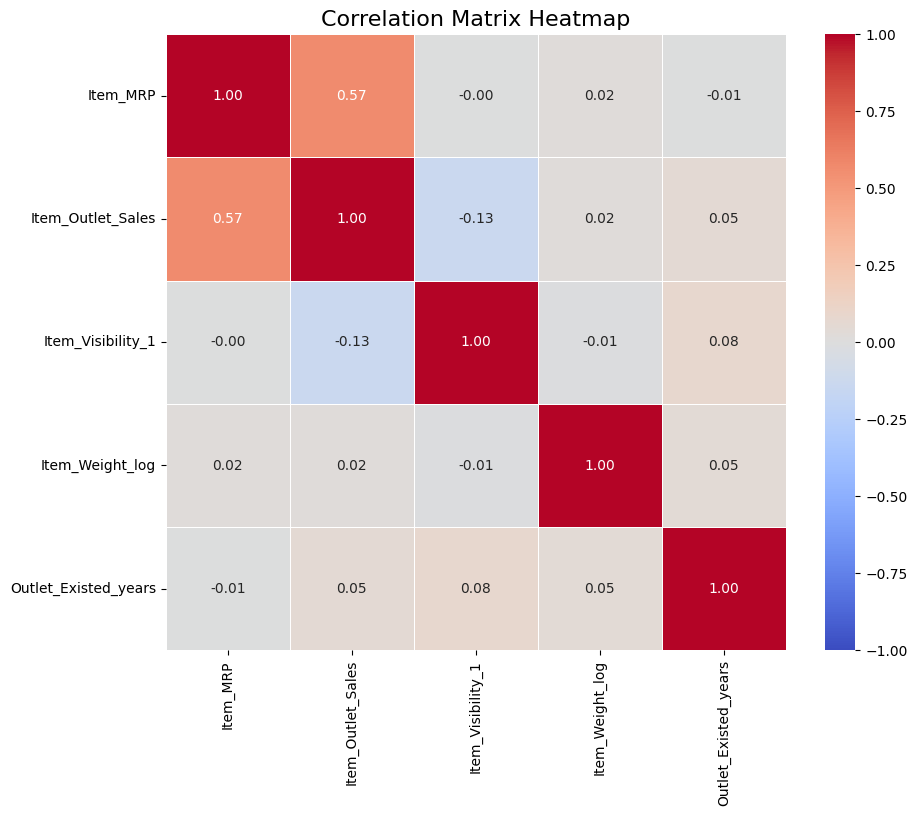

In [ ]:
#Check for multicollinearity
corr_matrix = df1.corr(numeric_only=True)

# 2. Set up the matplotlib figure
plt.figure(figsize=(10, 8))

# 3. Create a heatmap using Seaborn
sns.heatmap(
    corr_matrix,
    annot=True,          # Shows the correlation coefficients in each cell
    cmap='coolwarm',     # Color map (blue for negative, red for positive correlation)
    fmt=".2f",           # Round values to 2 decimal places
    linewidths=0.5,      # Adds subtle gridlines between cells
    vmin=-1, vmax=1      # Fixes the color scale limits between -1 and 1
)

# 4. Display the plot
plt.title("Correlation Matrix Heatmap", fontsize=16)
plt.show()

In [ ]:
from sklearn.model_selection import train_test_split

#for one hot encoding and scaling
from sklearn.preprocessing import OneHotEncoder,OrdinalEncoder, StandardScaler

#for target encoding
from sklearn.preprocessing import TargetEncoder

In [ ]:
X=df1.drop('Item_Outlet_Sales',axis=1)
Y=df1['Item_Outlet_Sales']

X_train,X_test,Y_train,Y_test=train_test_split(X,Y,test_size=0.2,random_state=42)

In [ ]:
#Item_Fat_Content - has no order present ie nominal (one-hot for linear and target for xgboost)
#Item_Type - different and unrelated values (one-hot for linear and target for xgboost)
#Outlet_Size - has an order present (ordinal encoding)
#Outlet_Location_Type - has an order present (ordinal encoding)
#Outlet_Type - has no order present ie nominal (one-hot for linear and target for xgboost)

In [ ]:
#Linear Encoding

In [ ]:
encoder = OneHotEncoder(drop='first', sparse_output=False)
cols_to_onehot = ['Item_Fat_Content', 'Item_Type', 'Outlet_Type']

encoded_train_array = encoder.fit_transform(X_train[cols_to_onehot])
encoded_train_df = pd.DataFrame(encoded_train_array, columns=encoder.get_feature_names_out(cols_to_onehot), index=X_train.index)
X_train_OEY_final = X_train.drop(columns=cols_to_onehot).join(encoded_train_df)

encoded_test_array = encoder.transform(X_test[cols_to_onehot])
encoded_test_df = pd.DataFrame(encoded_test_array, columns=encoder.get_feature_names_out(cols_to_onehot), index=X_test.index)
X_test_OEY_final = X_test.drop(columns=cols_to_onehot).join(encoded_test_df)

In [ ]:
cols_to_ordinal = ['Outlet_Size', 'Outlet_Location_Type']

size_order = ['Unknown','Small', 'Medium', 'High']
location_order = ['Tier 1', 'Tier 2', 'Tier 3']

categories_order = [size_order, location_order]

ord_encoder = OrdinalEncoder(categories=categories_order)

X_train_OEY_final[cols_to_ordinal] = ord_encoder.fit_transform(X_train_OEY_final[cols_to_ordinal])

X_test_OEY_final[cols_to_ordinal] = ord_encoder.transform(X_test_OEY_final[cols_to_ordinal])

In [ ]:
X_train_NOEY_final=X_train_OEY_final.drop('Outlet_Existed_years',axis=1)
X_test_NOEY_final=X_test_OEY_final.drop('Outlet_Existed_years',axis=1)

In [ ]:
X_train_NOEY_final.to_csv('X_train_NOEY_final.csv',index=False)
X_test_NOEY_final.to_csv('X_test_NOEY_final.csv',index=False)

In [ ]:
X_train_OEY_final.to_csv('X_train_OEY_final.csv',index=False)
X_test_OEY_final.to_csv('X_test_OEY_final.csv',index=False)

In [ ]:
Y_train.to_csv('Y_train.csv',index=False)
Y_test.to_csv('Y_test.csv',index=False)

In [ ]:
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.feature_selection import RFE
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.metrics import r2_score, root_mean_squared_error

def run_noey_pipeline(train_path, test_path, target_col='Item_Outlet_Sales'):
    print("Loading datasets...")
    train = pd.read_csv(train_path)
    test = pd.read_csv(test_path)

    # Extract features and target
    X_train = train.drop(columns=[target_col]).copy()
    y_train = train[target_col]
    X_test = test.drop(columns=[target_col]).copy()
    y_test = test[target_col]

    print("Cleaning categorical text labels...")
    fat_mapping = {'low fat': 'Low Fat', 'LF': 'Low Fat', 'reg': 'Regular', 'Regular': 'Regular'}
    X_train['Item_Fat_Content'] = X_train['Item_Fat_Content'].map(fat_mapping).fillna(X_train['Item_Fat_Content'])
    X_test['Item_Fat_Content'] = X_test['Item_Fat_Content'].map(fat_mapping).fillna(X_test['Item_Fat_Content'])

    print("Imputing Item_Weight using Item_Identifier group means (Train-derived)...")
    weight_lookup = X_train.groupby('Item_Identifier')['Item_Weight'].mean()
    global_weight_mean = X_train['Item_Weight'].mean()

    X_train['Item_Weight'] = X_train['Item_Weight'].fillna(X_train['Item_Identifier'].map(weight_lookup)).fillna(global_weight_mean)
    X_test['Item_Weight'] = X_test['Item_Weight'].fillna(X_test['Item_Identifier'].map(weight_lookup)).fillna(global_weight_mean)

    print("Imputing Outlet_Size using business cross-reference lookup matrix (Train-derived)...")
    def get_mode_matrix(df):
        mode_df = df.groupby(['Outlet_Type', 'Outlet_Location_Type'])['Outlet_Size'].agg(
            lambda x: x.mode().iloc[0] if not x.mode().empty else 'Small'
        ).reset_index()
        return mode_df

    size_mode_matrix = get_mode_matrix(X_train)
    global_size_mode = X_train['Outlet_Size'].mode().iloc[0] if not X_train['Outlet_Size'].mode().empty else 'Small'

    def impute_outlet_size(df, lookup_matrix, global_mode):
        df_merged = df.merge(lookup_matrix, on=['Outlet_Type', 'Outlet_Location_Type'], how='left', suffixes=('', '_mode'))
        df['Outlet_Size'] = df['Outlet_Size'].fillna(df_merged['Outlet_Size_mode']).fillna(global_mode)
        return df

    X_train = impute_outlet_size(X_train, size_mode_matrix, global_size_mode)
    X_test = impute_outlet_size(X_test, size_mode_matrix, global_size_mode)

    print("Mapping ordinal scales...")
    ordinal_mapping = {
        'Outlet_Size': {'Small': 1, 'Medium': 2, 'High': 3},
        'Outlet_Location_Type': {'Tier 1': 1, 'Tier 2': 2, 'Tier 3': 3}
    }
    for col, mapping in ordinal_mapping.items():
        X_train[col] = X_train[col].map(mapping)
        X_test[col] = X_test[col].map(mapping)

    print("Enforcing NOEY (Dropping temporal data & IDs)...")
    drop_cols = ['Item_Identifier']
    if 'Outlet_Establishment_Year' in X_train.columns:
        drop_cols.append('Outlet_Establishment_Year')

    X_train_lr = X_train.drop(columns=drop_cols)
    X_test_lr = X_test.drop(columns=drop_cols)

    nominal_cols = ['Item_Fat_Content', 'Item_Type', 'Outlet_Type']
    numeric_cols = ['Item_Weight', 'Outlet_Size', 'Outlet_Location_Type']

    print("Encoding nominal constraints via OneHotEncoder...")
    ohe = OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore')
    X_train_ohe = ohe.fit_transform(X_train_lr[nominal_cols])
    X_test_ohe = ohe.transform(X_test_lr[nominal_cols])

    ohe_feature_names = ohe.get_feature_names_out(nominal_cols)
    X_train_encoded = pd.concat([X_train_lr[numeric_cols].reset_index(drop=True), pd.DataFrame(X_train_ohe, columns=ohe_feature_names)], axis=1)
    X_test_encoded = pd.concat([X_test_lr[numeric_cols].reset_index(drop=True), pd.DataFrame(X_test_ohe, columns=ohe_feature_names)], axis=1)

    print("Scaling continuous structural space...")
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train_encoded)
    X_test_scaled = scaler.transform(X_test_encoded)

    # Invert distortion prep (log transform target)
    y_train_log = np.log1p(y_train)

    print("Compressing dimensions via Recursive Feature Elimination (RFE)...")
    lr_base = LinearRegression()
    rfe = RFE(estimator=lr_base, n_features_to_select=min(8, X_train_scaled.shape[1]), step=1)
    X_train_rfe = rfe.fit_transform(X_train_scaled, y_train_log)
    X_test_rfe = rfe.transform(X_test_scaled)

    print("Fitting basic Linear Regression model...")
    lr_model = LinearRegression()
    lr_model.fit(X_train_rfe, y_train_log)

    # Predict and invert the target log distribution
    preds_log = lr_model.predict(X_test_rfe)
    preds = np.expm1(preds_log)

    # Evaluation Metrics
    r2 = r2_score(y_test, preds)
    rmse = root_mean_squared_error(y_test, preds)

    print("\n" + "="*50)
    print("      LINEAR REGRESSION PERFORMANCE (NOEY)       ")
    print("="*50)
    print(f"  R2 Score: {r2:.4f}")
    print(f"  RMSE:     {rmse:.2f}")
    print("="*50)

if __name__ == '__main__':
    # Supply your actual filenames here
    TRAIN_CSV = '/content/X_train_NOEY_final.csv'
    TEST_CSV = '/content/X_test_NOEY_final.csv'

    run_noey_pipeline(TRAIN_CSV, TEST_CSV)

Loading datasets...


KeyError: "['Item_Outlet_Sales'] not found in axis"

In [ ]:
df1.to_csv("preprocessed_data.csv")